# Data Cleaning

In [1]:
from Bio import SeqIO
import os

input_file = 'data/all.train.fasta'
min_length = 50 
unwanted_char = 'X' # X in FASTA files mean unknown or unspecified amino acid, if the model encounters an X, it will throw an error, so filtering this is needed

## Inspecting a few records to understand raw data

In [2]:
# inspect first 3 sequences
records = list(SeqIO.parse(input_file, 'fasta'))
print(f'Total raw sequences  : {len(records)}')
print('='*50)
for record in records[:3]:
    print(f'ID: {record.id}\nLength: {len(record.seq)}\nSequence: {record.seq}\n')


Total raw sequences  : 5680
ID: non-allergen_3154
Length: 222
Sequence: MAAHTILASAPSHTTFSLISPFSSTPTNALSSSLQSSSFNGLSFKLSPTTQSLSLSTSAASKPLTIVAATKKAVAVLKGTSNVEGVVTLTQEDDGPTTVNVRISGLAPGKHGFHLHEFGDTTNGCMSTGPHFNPDKKTHGAPEDEVRHAGDLGNIVANTDGVAEATIVDNQIPLTGPNSVVGRALVVHELEDDLGKGGHELSPTTGNAGGRLACGVVGLTPV

ID: non-allergen_2914
Length: 269
Sequence: MAQFLRLCIWLLALGSCLLATVQADCSQDCAKCSYRLVRPGDINFLACTLECEGQLPSFKIWETCKDLLQVSKPEFPWDNIDMYKDSSKQDESHLLAKKYGGFMKRYGGFMKKMDELYPVEPEEEANGGEILAKRYGGFMKKDADEGDTLANSSDLLKELLGTGDNRAKDSHQQESTNNDEDSTSKRYGGFMRGLKRSPQLEDEAKELQKRYGGFMRRVGRPEWWMDYQKRYGGFLKRFAESLPSDEEGESYSKEVPEMEKRYGGFMRF

ID: non-allergen_19622
Length: 228
Sequence: MSSTTQAPEPVYQWTADEAVQFLKEWNFSLGIILLFITIILQFGYTSRSMFIYVVKMIILWLMWPLTIVLCIFNCVYALNNVYLGFSIVFTIVSIVIWIMYFVNSIRLFIRTGSWWSFNPETNNLMCIDMKGTVYVRPIIEDYHTLTATIIRGHLYMQGVKLGTGFSLSDLPAYVTVAKVSHLCTYKRAFLDKVDGVSGFAVYVKSKVGNYRLPSNKPSGADTALLRI



In [3]:
clean_sequences = []
short_sequences = []
unwanted_char_sequences = []

for record in records:
    # checking length and character exclusion
    if len(record.seq) >= min_length and unwanted_char not in str(record.seq).upper():
        clean_sequences.append(record)
    elif len(record.seq) < min_length: 
        short_sequences.append(str(record.seq))
    elif unwanted_char in str(record.seq).upper():
        unwanted_char_sequences.append(record.seq)
        
print(f'Thrown sequences:\n1. Too short: {list(short_sequences)}\n2. Unwanted char: {unwanted_char_sequences}')
print(f'Kept {len(clean_sequences)} out of {len(records)} sequences!')


Thrown sequences:
1. Too short: ['YTTEGGTKAEAEDVIPEGWKVDTSYE', 'VYYLATAPGEPSQR', 'RVDPCIGGVILFHETLYQKADDGRPFPQVIKS', 'PTLPGWNSPNCG', 'SYSQSYSYVQCIQDSECNGCWK', 'GIGAILKVLATGLPTLISWIKNKRKQ', 'IAKVPPGPNITADYGDKWLDAKSTWYGKPTGAGPK', 'VPSGTYGNKHECPCYRDKKNSKGKSKCP', 'FDKNQPWGVIRDLNVVNFKR', 'NMQVNPSGQVQPPQQQPFPQPQQ', 'AGDWVQTNVLAYSADVK', 'VSSTLSGLTGELK', 'LSPHVNPSATEYGLLLR', 'APAGGVVVAAMPPPL', 'GLTQKSAPWGLGADTIVAVELDSY', 'GGGDPTPACCGGVK', 'TQACRINSGNVPSELDLRSLRTVTPIRMQG', 'TVLAQATSKPDK', 'ILGRVIPKVAKKLGKT', 'DAGYTFDVAHTSVLTR', 'GRREDDYDNLQL', 'ADAGYTPAAPAATGAGGDAT', 'AVCNLFALEGATVIFTYVK', 'GPVGGVVHAHMMPLL', 'VAAGGWRPIEE', 'ATGKVVQDIMPPLLFVVQGKEKPSS', 'YTTEGGTKSEAEDVIPE', 'RFVIGGPHGDAGLTGRK', 'NVYNAIAAANLQGQIK', 'TPASGQPERKVAILG', 'FPGAHDEDSKERTLPLPPRSSMDTW', 'KKYSPEEIAMATVTALRRT', 'KCGMSVDLPPLDK', 'CGISIPYPISPSTNCSR', 'LVSVEHQAARLKVAKAQQLAAQLPAMCRLEGGDALSASQ', 'KDLYGNIVLSGGSTMFPGIADRM', 'IYDPDQATLQALR', 'SQQQQPPFSQQQPPFSQQQQPPFSQQQPPF', 'SALALVGNKVDTGR', 'SPDSDLEAFSHNPAHGSFAPLAFQPSAMTNCANQRFLS

## Batches Checking for DeepAlgPro

Code block below is to ensure that the dataset will not crash the DeepAlgPro model during training. DeepAlgPro is hardcoded to use default batch size of 72. If total number of sequences cannot be divided perfectly into groups of 72, the very last bath will be smaller than the rest (it will cause an error)

In [4]:
batch_size = 72
total_clean = len(clean_sequences)
remainder = total_clean % batch_size

print(f'Total sequences: {total_clean}')
print(f'Divisible by {batch_size}?\n--> {'Yes' if remainder == 0 else 'No'}')
if remainder != 0:
    print(f'You need to drop {remainder} sequences(s) to make it divisible by {batch_size}.')

Total sequences: 5505
Divisible by 72?
--> No
You need to drop 33 sequences(s) to make it divisible by 72.


## Save Cleaned FASTA Ouput

In [5]:
dir_name = os.path.dirname(input_file)
base_name = os.path.basename(input_file)
output_file = os.path.join(dir_name, 'cleaned_'+ base_name)
# print(dir_name, base_name)
print(f'Your output file: {output_file}')

valid_count = len(clean_sequences) - (len(clean_sequences) % batch_size)
print(valid_count)
final_sequences = clean_sequences[:valid_count]

SeqIO.write(final_sequences, output_file, 'fasta')
print(f'Saved {len(final_sequences)} valid sequences to {output_file} :) Time to work!')

Your output file: data\cleaned_all.train.fasta
5472
Saved 5472 valid sequences to data\cleaned_all.train.fasta :) Time to work!


### Learning Curves

In [6]:
! pip install matplotlib


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
import pandas as pd
import matplotlib.pyplot as plt

In [8]:
valid_file = 'model.1.fold.everyepoch.valid.txt'
metrics = ['loss', 'accuracy', 'recall', 'precision', 'auroc', 'f1']

df = pd.read_csv(valid_file, sep='\t', header=None, names=['epoch'] + metrics)
# train.py will append to this file instead of overwriting so every epoch goes back to 0 n new training run started
df['run'] = (df['epoch'] == 0).cumsum()
print(f'Found {df['run'].nunique()} training run(s) in {valid_file}')

Found 2 training run(s) in model.1.fold.everyepoch.valid.txt


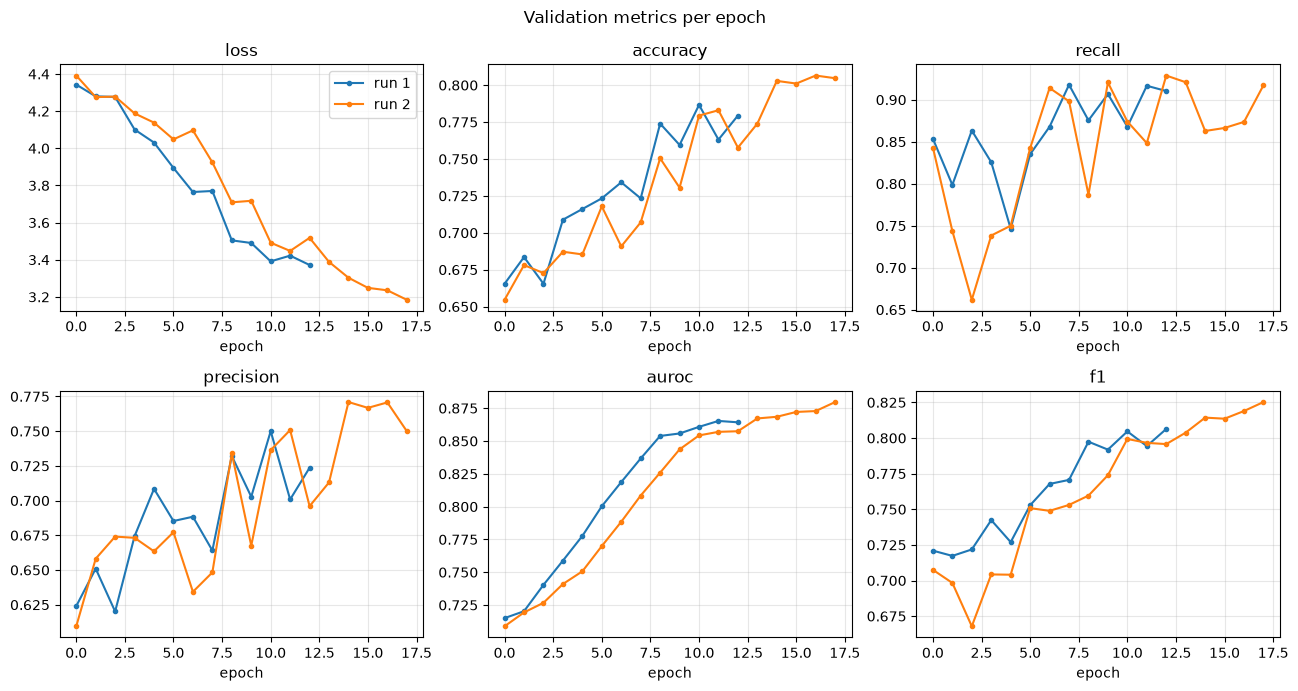

In [9]:
fig, axes = plt.subplots(2,3, figsize=(13,7))
for ax, metric in zip(axes.flat, metrics):
    for run, d in df.groupby('run'):
        ax.plot(d['epoch'], d[metric], marker='o', ms=3, label=f'run {run}')
    ax.set_title(metric)
    ax.set_xlabel('epoch')
    ax.grid(alpha=0.3)

axes.flat[0].legend()
fig.suptitle('Validation metrics per epoch')
plt.tight_layout()
plt.show()

In [24]:
from sklearn.metrics import roc_curve, precision_recall_curve, auc

def scores(net, x, batch= 64):
    net.eval()
    with torch.no_grad():
        return torch.cat([net(b) for b in torch.split(x, batch)]).squeeze(1).numpy()

p = scores(model, x) # model yang dipake itu model.pt 
fpr, tpr, _ = roc_curve(labels, p)
prec, rec, _ = precision_recall_curve(labels, p)
print('AUROC', auc(fpr, tpr), 'AUPRC', auc(rec, prec))

AUROC 0.9630489982146399 AUPRC 0.9692082953774871


## Data Visualization

In [10]:
import numpy as np, torch, matplotlib.pyplot as plt
import torch.nn.functional as F
from Bio import SeqIO
from explore_model import encode, codeadict, load_model

model, _ = load_model('model.pt') # load pretrained model

ids, seqs, labels = [], [], []
for rec in SeqIO.parse('data/all.test.fasta', 'fasta'):
    s = str(rec.seq).upper()

    if set(s) <= set(codeadict): #skip unrelevant sequences
        ids.append(rec.id); seqs.append(s)
        labels.append(1 if rec.id.startswith('allergen') else 0)
labels  = np.array(labels)
x = torch.tensor([encode(s) for s in seqs])
print(x.shape, 'allergen fraction:', labels.mean())


torch.Size([1420, 1000]) allergen fraction: 0.5


In [13]:
feats = {'input': [], 'conv': [], 'attn': [], 'fc': []}
hooks = [
    model.maxpool.register_forward_hook(lambda m, i, o: feats['conv'].append(i[0].flatten(1))),
    model.fc1.register_forward_hook(lambda m, i, o: feats['attn'].append(i[0])),
    model.fc1.register_forward_hook(lambda m,i,o: feats['fc'].append(o))
]

with torch.no_grad():
    for b in torch.split(x, 64):
        feats['input'].append(F.one_hot(b,21).float().flatten(1))
        model(b)
for h in hooks:
    h.remove()

feats = {k: torch.cat(v).numpy() for k, v in feats.items()}
for k, v in feats.items():
    print(k, v.shape)

input (1420, 21000)
conv (1420, 63040)
attn (1420, 23640)
fc (1420, 1)


In [14]:
from sklearn.decomposition import PCA
import umap
emb = {}

for k,v in feats.items():
    v_red = PCA(n_components=50, random_state=0).fit_transform(v) if v.shape[1] > 50 else v
    emb[k] = umap.UMAP(n_components=2, random_state=0).fit_transform(v_red)
    print(k,'done')

d:\TIF\is-lab\DeepAlgPro\venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


input done


d:\TIF\is-lab\DeepAlgPro\venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


conv done


d:\TIF\is-lab\DeepAlgPro\venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


attn done


d:\TIF\is-lab\DeepAlgPro\venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


fc done


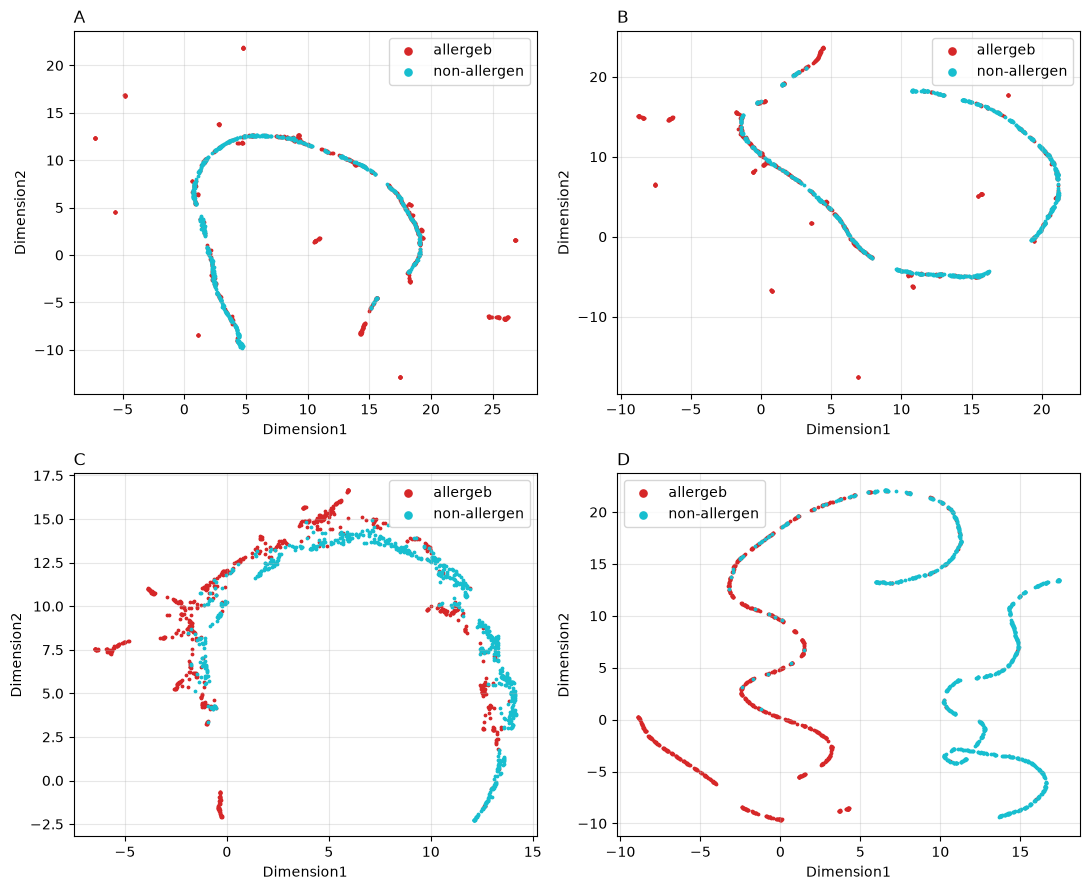

In [22]:
titles = {'input': 'A', 'conv': 'B', 'attn': 'C', 'fc': 'D'}   # keys must match feats

fig, axes = plt.subplots(2,2, figsize=(11,9))
for ax, (k,e) in zip(axes.flat, emb.items()):
    for lab, name, color in [(1, 'allergeb', 'tab:red'), (0, 'non-allergen', 'tab:cyan')]:
        m = labels == lab
        ax.scatter(e[m, 0], e[m,1], s=3, c=color, label = name)
    ax.set_title(titles[k], loc='left')
    ax.set_xlabel('Dimension1'); ax.set_ylabel('Dimension2')
    ax.grid(alpha=0.3); ax.legend(markerscale=3)

fig.tight_layout()
fig.savefig('umap_layers.png', dpi=200)